# 나만의 AI 에이전트 만들기

이 과제에서는 **실제로 동작하는 AI 에이전트**를 만듭니다!<br>
에이전트가 뉴스를 수집하고, 중요한 기사를 골라 요약한 뒤, 내 메일로 뉴스레터를 보내 줍니다.

## 과제 진행 순서와 제출물

1. **Step 0–1.** 내 계정으로 환경을 설정하고 기본 뉴스레터를 받아요.
2. **Step 2.** 기획란을 채우고, ① 설정 셀에서 항목을 두 가지 이상 직접 바꿔 나만의 뉴스레터를 받아요.
3. **Step 3.** ReAct 뉴스레터를 한 번 발송하고, 소스 하나를 실패시키는 실험을 따로 실행해 로그를 남겨요.
4. **Step 4–5.** Q1–Q6에 답하고, 완성한 노트북과 캡처 4장(메일 3장, Step 3 실험 로그 1장)을 함께 제출해요.

실행할 코드 셀은 Step 0부터 위에서 아래로 하나씩 진행하세요. Step 6은 읽기 자료입니다.

## 과제 구성

| 단계 | 내용 | 다음 행동을 정하는 주체 |
| --- | --- | --- |
| Step 0 | 환경 세팅 (API 키, Gmail 앱 비밀번호) | - |
| Step 1 | 뉴스 에이전트 파이프라인 만들기 | 코드 (고정 워크플로우) |
| Step 2 | 나만의 에이전트로 커스터마이징 | 코드 (고정 워크플로우) |
| Step 3 | ReAct 루프와 가드레일로 진짜 에이전트 만들기 | LLM |
| Step 4 | 강의 개념 확인 문제 | - |
| Step 5 | 결과 첨부 | - |
| Step 6 | 확장하기 (읽기만 하면 됩니다) | - |

## Step 1~2의 기본 흐름

```
뉴스 소스 접속 → 기사 목록 수집 → 중요 기사 선별(LLM) → 본문 크롤링 → 요약 정리(LLM) → 이메일 발송
```

## 준비물

| 항목 | 내용 |
| --- | --- |
| 환경 | VS Code + Python |
| LLM | Gemini API (무료) |
| 결과 전달 | Gmail SMTP |


---
## Step 0. 환경 세팅

### 0-1. 패키지 설치

In [ ]:
# 필요한 패키지 설치
!pip install google-genai requests beautifulsoup4 python-dotenv

### 0-2. Gemini API Key 발급

1. [Google AI Studio](https://aistudio.google.com/apikey)에 접속
2. **Create API Key** 클릭
3. 발급된 키를 복사

### 0-3. Gmail 앱 비밀번호 발급

이 과제에서 Gmail로 뉴스레터를 보내려면 **개인 Gmail 계정의 앱 비밀번호**가 필요합니다.

1. [Google 계정 관리](https://myaccount.google.com/)에서 사용할 개인 Gmail 계정으로 로그인하세요.
2. **보안**에서 **2단계 인증**이 켜져 있는지 확인하세요. 꺼져 있으면 켜 주세요.
3. 같은 계정으로 [앱 비밀번호 페이지](https://myaccount.google.com/apppasswords)를 여세요. Google에서 본인 확인을 요청하면 화면 안내에 따라 완료하세요.
4. 이 안내 바로 다음에 있는 예시처럼 **앱 이름**에 `news-agent`를 입력하고 **만들기**를 누르세요.
5. 생성된 앱 비밀번호를 복사한 뒤 다음 단계에서 `.env`의 `GMAIL_APP_PASSWORD`에 공백 없이 넣으세요. `GMAIL_ADDRESS`에는 앱 비밀번호를 발급한 계정의 Gmail 주소를 넣으세요.

**‘찾고 있는 설정을 계정에서 사용할 수 없습니다’가 뜨면**

- 오른쪽 위 프로필에서 개인 Gmail 계정이 선택되어 있는지 확인하세요. 여러 계정에 로그인되어 있다면 Chrome 시크릿 창에서 사용할 개인 Gmail 계정 하나로 로그인한 뒤 앱 비밀번호 페이지를 다시 열어 보세요.
- 같은 계정에서 **2단계 인증**이 켜져 있는지 확인하세요. 학교나 회사 계정, 고급 보호가 설정된 계정, 보안 키만으로 2단계 인증을 설정한 계정에서는 메뉴가 표시되지 않을 수 있습니다. [Google 앱 비밀번호 도움말](https://support.google.com/accounts/answer/185833?hl=ko)
- 앱 비밀번호가 발급되면 바로 `.env`에 저장하세요. 발급된 비밀번호나 `.env` 파일은 캡처나 과제 제출물에 포함하지 마세요.

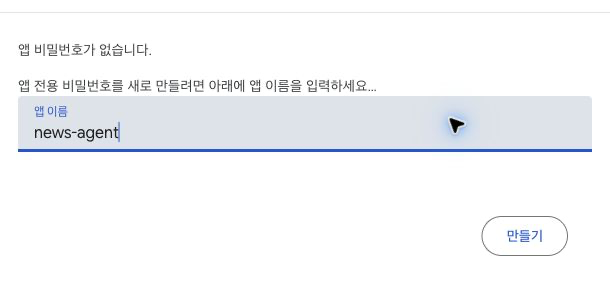

In [ ]:
# 앱 비밀번호 발급 화면 예시입니다. 이 셀은 실행하지 않고 아래 이미지만 확인하세요.

### 0-4. `.env` 파일 채우기

이 노트북과 같은 폴더에 `.env` 파일을 만들고 아래 내용을 채워주세요.

```
GEMINI_API_KEY="여기에_제미나이_API_키"
GMAIL_ADDRESS="내이메일@gmail.com"
GMAIL_APP_PASSWORD="여기에_16자리_앱비밀번호"
```

> ⚠️ `.env` 파일은 GitHub에 올리지 마세요!

In [ ]:
import os
from dotenv import load_dotenv

load_dotenv(override=True)  # .env 파일에서 환경변수 로드

GEMINI_API_KEY = os.getenv("GEMINI_API_KEY")
GMAIL_ADDRESS = os.getenv("GMAIL_ADDRESS")
GMAIL_APP_PASSWORD = os.getenv("GMAIL_APP_PASSWORD")

# 변수 이름과 설정 여부만 확인합니다.
for name in ("GEMINI_API_KEY", "GMAIL_ADDRESS", "GMAIL_APP_PASSWORD"):
    print(f"{name}: {'설정됨' if os.getenv(name) else '없음'}")

In [ ]:
# Gemini 클라이언트 초기화
MODEL = "gemini-2.5-flash"  # 모델 변경은 여기 한 줄만 수정
from google import genai

os.environ["GEMINI_API_KEY"] = GEMINI_API_KEY  # genai가 참조하는 환경변수
from google.genai import types

# 503(서버 혼잡) 등 일시적 오류 시 자동 재시도 (최대 5회, 간격 점점 늘림)
client = genai.Client(
    api_key=GEMINI_API_KEY,
    http_options=types.HttpOptions(
        api_version="v1beta",  # 함수 호출(Tool Calling)은 v1beta에서만 지원돼요
        retry_options=types.HttpRetryOptions(attempts=5, initial_delay=2, max_delay=30)
    ),
)

# 테스트
response = client.models.generate_content(
    model=MODEL,
    contents="안녕! 한 줄로 자기소개 해줘."
)
print(response.text)

---
## Step 1. 뉴스 에이전트 파이프라인 만들기

에이전트가 수행할 작업 흐름:

```
1) 뉴스 섹션 페이지 크롤링 → 기사 제목 + 링크 수집
2) LLM이 중요한 기사 선별
3) 선별된 기사 본문 크롤링
4) LLM이 뉴스레터 형태로 요약
5) Gmail로 발송
```

각 단계를 함수로 만들고, 마지막에 하나로 연결합니다.

### 1-1. 뉴스 목록 수집

In [ ]:
import re
import requests
from datetime import datetime
from bs4 import BeautifulSoup

HEADERS = {"User-Agent": "Mozilla/5.0 (Windows NT 10.0; Win64; x64) AppleWebKit/537.36"}


def fetch_news_list(section_url: str,
                    link_selector: str = "a[href*='/article/']",
                    base_url: str = "https://news.naver.com") -> list[dict]:
    """
    뉴스 섹션 페이지에서 기사 제목과 링크를 수집합니다.

    Args:
        section_url: 뉴스 섹션 URL (예: https://news.naver.com/section/105)
        link_selector: 기사 링크(<a> 태그)를 찾는 CSS selector (기본값: 네이버 뉴스)
        base_url: 링크가 "/"로 시작할 때 앞에 붙일 주소

    Returns:
        [{"title": 기사제목, "url": 기사URL}, ...]
    """
    resp = requests.get(section_url, headers=HEADERS, timeout=10)
    resp.raise_for_status()

    soup = BeautifulSoup(resp.text, "html.parser")

    articles = []
    seen_urls = set()

    for a_tag in soup.select(link_selector):
        title = a_tag.get_text(strip=True)
        href = a_tag.get("href", "")

        # 제목이 너무 짧거나 중복이면 스킵
        if len(title) < 5 or not href or href in seen_urls:
            continue

        # 상대 경로 처리
        if href.startswith("/"):
            href = base_url + href

        seen_urls.add(href)
        articles.append({"title": title, "url": href})

    return articles


# 테스트: IT/과학 섹션
news_list = fetch_news_list("https://news.naver.com/section/105")
print(f"수집된 기사 수: {len(news_list)}개\n")
for i, article in enumerate(news_list[:5]):
    print(f"{i+1}. {article['title']}")
    print(f"   {article['url']}")

### 1-2. LLM으로 중요 기사 선별

In [ ]:
# 기본 선별 기준 (Step 2에서는 내 기준으로 바꿔 넣습니다)
DEFAULT_CRITERIA = """- 사회적 영향력이 큰 기사
- 기술 트렌드를 보여주는 기사
- 독자의 관심도가 높을 만한 기사
- 비슷한 내용의 기사가 여럿이면 하나만 고르세요"""


def select_top_articles(articles: list[dict], n: int = 5, criteria: str = DEFAULT_CRITERIA) -> list[int]:
    """
    LLM이 기사 목록에서 가장 중요한 N개를 선별합니다.

    Args:
        articles: fetch_news_list()의 결과
        n: 선별할 기사 수
        criteria: 선별 기준 (여러 줄 텍스트)

    Returns:
        선별된 기사의 인덱스 리스트
    """
    # 기사 목록을 텍스트로 변환
    article_list_text = "\n".join(
        f"{i}. {a['title']}" for i, a in enumerate(articles)
    )

    # 프롬프트는 "역할 → 할 일 → 선별 기준 → 출력 형식 → 입력" 순서로 구조화하면 결과가 안정적이에요.
    prompt = f"""## 역할 (Role)
당신은 뉴스 큐레이터입니다. 바쁜 독자가 꼭 읽어야 할 기사만 골라줍니다.

## 해야 할 일 (Task)
아래 [기사 목록]에서 오늘 가장 중요하고 흥미로운 기사 {n}개를 고르세요.

## 선별 기준 (Criteria)
{criteria}

## 출력 형식 (Output Format)
- 반드시 숫자 인덱스만 콤마로 구분해서 답하세요 (설명, 제목, 다른 글자 금지)
- 예시: 0, 3, 7, 12, 15

## 기사 목록 (Input)
{article_list_text}

선별 결과 (인덱스만):"""

    response = client.models.generate_content(
        model=MODEL,
        contents=prompt
    )

    # 응답에서 숫자를 추출하고, 유효한 인덱스만 남깁니다
    indices = [int(x) for x in re.findall(r'\d+', response.text)]
    return [i for i in indices if 0 <= i < len(articles)][:n]


In [ ]:
# 테스트
selected_indices = select_top_articles(news_list, n=5)
print(f"LLM이 선별한 기사 인덱스: {selected_indices}\n")
for idx in selected_indices:
    print(f"- {news_list[idx]['title']}")

### 1-3. 기사 본문 크롤링

In [ ]:
def fetch_article_body(url: str) -> str:
    """
    개별 뉴스 기사 URL에서 본문 텍스트를 추출합니다.
    """
    resp = requests.get(url, headers=HEADERS, timeout=10)
    resp.raise_for_status()
    
    soup = BeautifulSoup(resp.text, "html.parser")
    
    # 네이버 뉴스 본문 영역
    body = soup.select_one("#newsct_article") or soup.select_one("#articeBody") or soup.select_one("article")
    
    if body:
        # 불필요한 태그 제거
        for tag in body(["script", "style", "iframe", "figure"]):
            tag.decompose()
        text = body.get_text(separator="\n", strip=True)
    else:
        # fallback: 전체 페이지에서 추출
        for tag in soup(["script", "style", "nav", "footer", "header"]):
            tag.decompose()
        text = soup.get_text(separator="\n", strip=True)
    
    # 너무 길면 자르기
    if len(text) > 3000:
        text = text[:3000] + "\n\n... (이하 생략)"
    
    return text

In [ ]:
# 테스트: 선별된 첫 번째 기사
if selected_indices:
    test_url = news_list[selected_indices[0]]["url"]
    test_body = fetch_article_body(test_url)
    print(f"기사: {news_list[selected_indices[0]]['title']}")
    print(f"본문 길이: {len(test_body)}자")
    print(f"\n{test_body[:300]}...")

### 1-4. LLM으로 뉴스레터 생성

In [ ]:
def strip_code_fence(text: str) -> str:
    """LLM이 ```html ... ``` 로 감싸서 답하면 코드블록 표시를 벗겨냅니다."""
    text = text.strip()
    if text.startswith("```"):
        text = text.split("\n", 1)[1] if "\n" in text else text
        text = text.rsplit("```", 1)[0]
    return text.strip()


def render_prompt(template: str, agent_name: str, articles: str = "") -> str:
    """
    프롬프트 템플릿의 빈칸 {agent_name}, {today}, {articles} 를 채웁니다.
    - LLM은 오늘 날짜를 모르기 때문에, 파이썬에서 날짜를 만들어 프롬프트에 직접 알려줘야 해요.
    - replace를 쓰므로 프롬프트 안에 { } 가 있어도 안전해요.
    """
    return (
        template
        .replace("{articles}", articles)
        .replace("{agent_name}", agent_name)
        .replace("{today}", datetime.now().strftime("%Y-%m-%d"))
    )


# 프롬프트는 "역할 → 할 일 → 구성 → 디자인 → 규칙 → 입력" 순서로 구조화하면 원하는 결과를 얻기 쉬워요.
# (Step 2에서는 이 구조를 그대로 가져가 내용만 바꿔보세요!)
DEFAULT_NEWSLETTER_PROMPT = """## 역할 (Role)
당신은 IT, 과학 분야 뉴스레터 에디터입니다.

## 해야 할 일 (Task)
아래 [기사들]을 읽고, 독자가 빠르게 훑어볼 수 있는 뉴스레터를 HTML 형식으로 작성하세요.
- 각 기사를 3~4줄로 요약
- 핵심 포인트를 명확하게 드러내기

## 전체 구성 (Structure)
- 맨 위: 날짜({today})와 "{agent_name}" 제목 (날짜는 반드시 {today} 그대로 쓰기)
- 본문: 기사별 제목 → 요약 → 원문 링크 순서

## 디자인 (Design)
- 전체를 하나의 HTML로, 인라인 스타일만 사용 (메일에서는 CSS 파일이 적용되지 않아요)
- 폰트: 'Malgun Gothic', 'Apple SD Gothic Neo', Arial, sans-serif / 본문 15px / 줄 간격 1.6
- 전체 폭 최대 600px, 가운데 정렬, 흰 배경, 바깥 여백 20px
- 상단 제목은 24px 굵게, 포인트 색은 파란색(#2563eb), 날짜는 회색(#888) 작은 글씨
- 기사 사이는 연한 회색 가는 선(#e5e5e5)으로 구분, 기사 제목은 18px 굵게
- '원문 보기'는 파란 글씨 링크로 표시

## 지켜야 할 규칙 (Rules)
- 한국어로 작성
- 각 기사에 원문 링크 포함
- 기사 본문에 없는 내용은 쓰지 않기
- 코드블록(```)이나 설명 없이 HTML만 출력

## 기사들 (Input)
{articles}"""


def generate_newsletter(articles_data: list[dict],
                        prompt_template: str = DEFAULT_NEWSLETTER_PROMPT,
                        agent_name: str = "오늘의 IT 뉴스 브리핑") -> str:
    """
    크롤링된 기사들을 LLM이 뉴스레터 형태로 정리합니다.

    Args:
        articles_data: [{"title": ..., "url": ..., "body": ...}, ...]
        prompt_template: 프롬프트 템플릿 ({agent_name}, {today}, {articles} 빈칸 사용)
        agent_name: 뉴스레터 이름

    Returns:
        뉴스레터 텍스트 (HTML 형식)
    """
    articles_text = ""
    for i, a in enumerate(articles_data, 1):
        articles_text += f"\n---\n기사 {i}: {a['title']}\nURL: {a['url']}\n본문:\n{a['body']}\n"

    prompt = render_prompt(prompt_template, agent_name, articles_text)
    response = client.models.generate_content(model=MODEL, contents=prompt)
    return strip_code_fence(response.text)


In [ ]:
# 테스트 (선별된 기사 2개로 테스트)
test_articles = []
for idx in selected_indices[:2]:
    body = fetch_article_body(news_list[idx]["url"])
    test_articles.append({
        "title": news_list[idx]["title"],
        "url": news_list[idx]["url"],
        "body": body
    })

newsletter_html = generate_newsletter(test_articles)
print(newsletter_html[:500])

### 1-5. 이메일 발송

In [ ]:
import smtplib
from email.mime.multipart import MIMEMultipart
from email.mime.text import MIMEText


def send_email(to_email: str, subject: str, html_body: str) -> bool:
    """
    Gmail SMTP를 통해 HTML 이메일을 발송합니다.
    
    Args:
        to_email: 받는 사람 이메일
        subject: 메일 제목
        html_body: HTML 형식의 메일 본문
    
    Returns:
        성공 여부
    """
    msg = MIMEMultipart("alternative")
    msg["From"] = GMAIL_ADDRESS
    msg["To"] = to_email
    msg["Subject"] = subject
    
    # HTML 본문 첨부
    msg.attach(MIMEText(html_body, "html", "utf-8"))
    
    try:
        with smtplib.SMTP("smtp.gmail.com", 587) as server:
            server.starttls()
            server.login(GMAIL_ADDRESS, GMAIL_APP_PASSWORD)
            server.send_message(msg)
        print("메일 발송 성공!")
        return True
    except Exception as e:
        print(f"메일 발송 실패: {e}")
        return False


# 아직 실행하지 마세요! 아래 전체 파이프라인에서 한번에 실행합니다.
print("send_email 함수 정의 완료 ")

### 1-6. 전체 파이프라인 실행

위에서 만든 함수들을 하나로 연결합니다.  
**이 셀을 실행하면 실제로 메일이 발송됩니다!**

In [ ]:
def run_news_agent(section_urls,
                   to_email: str,
                   num_articles: int = 5,
                   criteria: str = DEFAULT_CRITERIA,
                   prompt_template: str = DEFAULT_NEWSLETTER_PROMPT,
                   agent_name: str = "오늘의 IT 뉴스 브리핑",
                   link_selector: str = "a[href*='/article/']",
                   base_url: str = "https://news.naver.com"):
    """
    뉴스 에이전트 전체 파이프라인을 실행합니다.
    (Step 2에서는 이 함수에 내 설정값만 바꿔 넣어 그대로 재사용합니다)

    Args:
        section_urls: 뉴스 섹션 URL (문자열 하나 또는 리스트)
        to_email: 뉴스레터를 받을 이메일 주소
        num_articles: 선별할 기사 수
        criteria: 기사 선별 기준
        prompt_template: 뉴스레터 작성 프롬프트
        agent_name: 에이전트(뉴스레터) 이름
        link_selector, base_url: 기사 링크를 찾는 규칙 (fetch_news_list 참고)
    """
    if isinstance(section_urls, str):
        section_urls = [section_urls]

    print("=" * 50)
    print(f"{agent_name} 시작")
    print("=" * 50)

    # 1단계: 뉴스 목록 수집 (여러 소스는 합칩니다)
    print("\n[1/5] 뉴스 목록 수집 중...")
    news_list = []
    for url in section_urls:
        try:
            news_list += fetch_news_list(url, link_selector, base_url)
        except Exception as e:
            print(f"   수집 실패: {url} ({e})")
    print(f"   -> {len(news_list)}개 기사 발견")

    if not news_list:
        print("기사를 찾을 수 없습니다. URL과 selector를 확인해주세요.")
        return

    # 2단계: 중요 기사 선별
    print(f"\n[2/5] LLM이 상위 {num_articles}개 기사 선별 중...")
    selected = select_top_articles(news_list, n=num_articles, criteria=criteria)
    for idx in selected:
        print(f"   - {news_list[idx]['title']}")

    # 3단계: 선별 기사 본문 크롤링
    print("\n[3/5] 선별 기사 본문 크롤링 중...")
    articles_data = []
    for idx in selected:
        item = news_list[idx]
        try:
            body = fetch_article_body(item["url"])
            articles_data.append({"title": item["title"], "url": item["url"], "body": body})
            print(f"   - {item['title'][:40]}... ({len(body)}자)")
        except Exception as e:
            print(f"   크롤링 실패: {item['title'][:30]}... ({e})")

    if not articles_data:
        print("본문을 가져온 기사가 없습니다.")
        return

    # 4단계: 뉴스레터 생성
    print("\n[4/5] 뉴스레터 생성 중...")
    newsletter = generate_newsletter(articles_data, prompt_template, agent_name)
    print(f"   -> 뉴스레터 생성 완료 ({len(newsletter)}자)")

    # 5단계: 이메일 발송
    today = datetime.now().strftime("%Y-%m-%d")
    print("\n[5/5] 이메일 발송 중...")
    send_email(to_email, f"[{agent_name}] {today}", newsletter)

    print("\n" + "=" * 50)
    print("에이전트 작업 완료")
    print("=" * 50)

    return newsletter


In [ ]:
# 실행! (본인 이메일로 발송됩니다)
newsletter = run_news_agent(
    section_urls=["https://news.naver.com/section/105"],  # IT/과학 섹션
    to_email=GMAIL_ADDRESS,  # .env에 설정한 본인 이메일
    num_articles=5,
)

---
## Step 2. 나만의 에이전트 커스터마이징

Step 1의 뉴스 에이전트를 바탕으로 **나만의 에이전트**를 만듭니다.
아래 항목 중 **두 가지 이상**을 직접 바꾸고, 2-1 기획란에 각 항목을 어떻게 바꿨는지 적어 주세요. 제공된 예시를 그대로 실행한 결과는 변경 항목에 포함되지 않습니다.

| 변경 항목 | 아이디어 예시 |
| --- | --- |
| 소스 | 다른 뉴스 섹션(경제, 사회, 세계), 특정 언론사, 기술 블로그(GeekNews, 44bits 등), 채용 공고, 학교 공지사항 등 |
| 처리 방식 | 선별 기준 변경(특정 키워드 우선, 긍/부정 필터링), 요약 대신 비교, 감성 분석, 키워드 추출, 여러 소스 종합 |
| 출력 형식 | 뉴스레터 디자인, 카테고리별 분류, 한 줄 요약 + 중요도 점수 |
| 시스템 프롬프트 | 역할 부여("IT 전문 기자", "투자 애널리스트" 등), 말투, 분석 관점 지정 |


### 2-1. 내 에이전트 기획

아래에 본인 에이전트의 기획을 적어주세요.

**내 에이전트 이름:** (예: 취준 뉴스봇, 주식 모닝브리핑 등)

**목적:** 

**데이터 소스 (URL):** 

**변경한 부분:**
- [ ] 소스 변경
- [ ] 처리 방식 변경  
- [ ] 출력 형식 변경
- [ ] 시스템 프롬프트 커스텀
- [ ] 기타: 

**한 줄 설명:** 

### 2-2. 내 에이전트 코드

> **어디서부터 시작하죠?**
> 아래 셀을 **위에서부터 순서대로 실행**하면 에이전트가 완성됩니다. 코드를 처음부터 쓸 필요가 없어요.

| 순서 | 셀 | 하는 일 | 내가 할 일 |
| --- | --- | --- | --- |
| ① | 설정 | 이름, 소스 URL, 선별 기준, 요약 프롬프트 | 내 기획에 맞게 수정하고 실행 |
| ② | 목록 수집 확인 | 기사 제목과 링크가 수집되는지 확인 | ①에서 정한 소스가 작동하는지 확인 |
| ③ | 실행 | Step 1의 파이프라인(`run_news_agent`)을 내 설정으로 실행하고 메일 발송 | 받은 메일을 열어 Step 5에 첨부할 캡처 저장 |

**프롬프트 고치는 요령**
- `MY_SUMMARY_PROMPT`는 역할 → 독자 → 말투 → 할 일 → 구성 → 디자인 → 규칙 순서로 나뉘어 있습니다. 섹션별 `# 힌트:` 줄을 보고 원하는 부분만 바꿔 쓰세요.
- 결과가 마음에 들지 않으면 해당 섹션을 더 **구체적으로** 적는 것이 가장 효과적입니다.
- `{articles}` 빈칸은 지우지 마세요. 기사가 전달되지 않습니다.

**Step 1의 함수를 그대로 가져다 씁니다.** 새로 짤 코드는 없지만, Step 1 셀들을 먼저 실행해 두어야 합니다.
- `run_news_agent`: 수집 → 선별 → 크롤링 → 요약 → 발송 전체 파이프라인
- `client`, `MODEL`: Gemini 연결


### ① 설정

아래 코드는 네이버 경제 섹션을 사용하는 시작 예시예요. 바꿀 항목을 고른 뒤 설정 셀을 실행하고, ②에서 기사 목록을 확인하세요.

- 뉴스 소스는 `MY_SOURCE_URLS`에서 바꿔요.
- 기사 선별 기준은 `MY_SELECT_CRITERIA`에서 바꿔요.
- 출력 형식은 `MY_SUMMARY_PROMPT`의 구성과 디자인에서, 역할과 말투는 같은 프롬프트의 역할과 말투에서 바꿔요.

In [ ]:
# 1) 이름, 받는 사람
MY_AGENT_NAME = "(예시)취뽀를 위한 산업 동향 브리핑"          # 메일 제목/본문 상단에 쓰입니다
MY_TO_EMAIL = GMAIL_ADDRESS                    # 받는 사람 (기본: 내 메일)

# 2) 소스 변경 — 어디서 가져올까?
MY_SOURCE_URLS = [
    "https://news.naver.com/section/101",  # 예시: 네이버 경제. 내 기획에 맞는 소스로 바꿔 보세요.
    # "소스 링크 2",    # 여러 소스를 쓰려면 줄을 추가하세요
    # "...",
]
MY_LINK_SELECTOR = "a[href*='/article/']"      # 기사 링크를 찾는 규칙 (네이버 뉴스는 그대로 OK)
MY_BASE_URL = "https://news.naver.com"         # 링크가 "/로 시작"할 때 앞에 붙일 주소
MY_NUM_ARTICLES = 5                            # 몇 개를 뽑을지

# 3) 처리 방식 변경 — 어떤 기사를 고를까?
MY_SELECT_CRITERIA = """
- 취업/채용, 산업 동향, 신기술과 관련된 기사를 우선
- 연예, 스포츠, 단순 사건사고는 제외
"""

# 4) 요약, 출력 프롬프트 — LLM에게 주는 "작업 지시서" 전체입니다. 이 부분이 에이전트의 개성을 결정해요!
#    아래 예시를 통째로 읽어보고, 마음에 안 드는 부분을 고쳐 쓰세요. (섹션별로 무엇을 바꾸면 좋은지 '# 힌트:' 줄로 적어뒀어요)
#
#    ※ 반드시 남겨둘 것:  {articles}  ← 선별된 기사들이 들어가는 자리 (지우면 기사가 전달되지 않아요!)
#    ※ 쓸 수 있는 빈칸:   {agent_name} = 위 MY_AGENT_NAME,  {today} = 오늘 날짜
#    ※ 프롬프트 안의 "# 힌트: ..." 줄은 설명용이니 지워도 되고, 그대로 둬도 괜찮아요.
MY_SUMMARY_PROMPT = """
## 역할 (Role)
# 힌트: 누구의 관점으로 쓸지 정해주세요. 예) "투자 애널리스트", "IT 전문 기자", "친구에게 설명해주는 선배"
(예시)당신은 취업 준비생을 위한 산업 분석 전문 에디터입니다. 이해하기 쉽게 풀어 설명하며 핵심 인사이트를 정확하게 뽑아냅니다.

## 독자 (Audience)
# 힌트: 읽는 사람이 누구인지 알려주면 눈높이와 내용 선택이 달라져요.
독자는 IT, 경제 분야 취업을 준비하는 대학생입니다. 전문 용어는 쉬운 말로 풀어서 설명하세요.

## 말투 (Tone)
# 힌트: 예) "존댓말, 간결하게", "유머러스한 반말", "객관적인 기자체"
친근하지만 정확한 존댓말을 사용하세요. 과장이나 추측은 하지 마세요.

## 해야 할 일 (Task)
# 힌트: 기사로 '무엇'을 할지: 요약 / 비교 분석 / 감성 분석 / 키워드 추출 / 찬반 정리 등
아래 [기사들]을 읽고 뉴스레터를 만드세요. 기사마다 다음을 작성합니다.
1. 한 줄 요약 (30자 내외)
2. 핵심 포인트 2개 (각 1~2문장)
3. '취준생에게 의미' 한 줄
4. 중요도: ⭐ 1~5개

## 전체 구성 (Structure)
# 힌트: 메일의 순서와 구성요소를 정하세요. 카테고리별로 묶거나, 중요도순으로 정렬하라고 시킬 수도 있어요.
- 맨 위: "{agent_name}" 제목과 날짜({today})
- 본문: 기사를 중요도 높은 순서로 나열
- 맨 아래: '오늘의 한 줄 인사이트' (기사들을 관통하는 시사점)

## 디자인 (Design)
# 힌트: 색상, 폰트, 카드 형태 등을 구체적으로 적을수록 원하는 모양이 나와요. 예) "파란색 포인트, 둥근 카드"
- 전체를 하나의 HTML로, 인라인 스타일만 사용 (메일에서는 CSS 파일이 적용되지 않아요)
- 폰트: 'Malgun Gothic', 'Apple SD Gothic Neo', Arial, sans-serif / 본문 15px / 줄 간격 1.7 / 글자색 #222
- 전체 폭 최대 700px, 가운데 정렬, 배경은 연한 회색(#f5f6f8), 안쪽 흰색 영역 위에 카드를 배치
- 헤더: 파란 배경(#2563eb)에 흰색 굵은 제목(24px)과 날짜(13px, 반투명 흰색)
- 기사 카드: 흰 배경, 1px 연한 테두리(#e5e7eb), 둥근 모서리 12px, 안쪽 여백 20px, 카드 사이 간격 16px
- 카드 안: 기사 제목(18px, 굵게) → 중요도 별(주황색 #f59e0b) → 요약 → 핵심 포인트(점 목록)
- 각 카드 끝에 '원문 보기' 버튼: 파란 배경(#2563eb), 흰 글씨, 둥근 모서리 6px, 위아래 8px 좌우 16px 여백
- 맨 아래 '오늘의 한 줄 인사이트'는 연한 파란 배경(#eff6ff) 박스에 담기

## 지켜야 할 규칙 (Rules)
# 힌트: 하지 말아야 할 것도 적어두면 좋아요. 예) "기사에 없는 내용 지어내지 않기", "이모지 금지"
- 반드시 한국어로 작성
- 기사 본문에 없는 내용은 쓰지 않기
- 코드블록(```)이나 설명 없이 HTML만 출력

## 기사들 (Input)
{articles}
"""

print(f"설정 완료: {MY_AGENT_NAME}")

### ② 목록 수집 확인

- 네이버 뉴스 섹션만 쓴다면 그대로 실행하세요.
- 다른 사이트를 쓰려면 ①의 `MY_LINK_SELECTOR`, `MY_BASE_URL`만 바꾸면 되는 경우가 많습니다.
- selector 찾는 법: 크롬에서 기사 제목 우클릭 → 검사 → `<a>` 태그 확인. 또는 AI에게 "이 HTML에서 기사 링크 selector 알려줘"라고 물어보세요.

In [ ]:
def check_source_urls() -> bool:
    """① 설정의 MY_SOURCE_URLS 가 실제 URL로 바뀌었는지 확인합니다. (아직 '소스 링크' 같은 예시면 안내 후 False)"""
    bad = [u for u in MY_SOURCE_URLS if not u.strip().startswith(("http://", "https://"))]
    if bad or not MY_SOURCE_URLS:
        print("주의: 아직 소스 URL이 설정되지 않았어요!")
        print(f"   현재 값: {bad if bad else '(비어 있음)'}")
        print("   -> ① 설정 셀의 MY_SOURCE_URLS 를 실제 주소로 바꾼 뒤, ① 셀부터 다시 실행해 주세요.")
        print("   예) \"https://news.naver.com/section/101\"  (105=IT/과학, 101=경제, 102=사회, 104=세계)")
        return False
    return True


# 테스트: 목록이 잘 모이는지 확인 (0개면 selector/URL을 다시 확인!)
if check_source_urls():
    _test = fetch_news_list(MY_SOURCE_URLS[0], MY_LINK_SELECTOR, MY_BASE_URL)
    print(f"수집된 항목: {len(_test)}개")
    for t in _test[:3]:
        print("-", t["title"], t["url"])

### ③ 실행

- ①, ② 셀을 먼저 실행하세요.
- **주의:** 실행하면 실제로 메일이 발송됩니다.
- 단계를 추가하고 싶다면(키워드 필터, 점수 계산 등) Step 1의 `run_news_agent`를 복사해서 고쳐 쓰세요.

In [ ]:
def run_my_agent():
    """① 설정대로 Step 1의 파이프라인(run_news_agent)을 실행합니다."""
    # 시작 전 점검: 소스 URL이 예시 그대로면 안내 후 중단 (메일도 보내지 않아요)
    if not check_source_urls():
        return

    return run_news_agent(
        section_urls=MY_SOURCE_URLS,
        to_email=MY_TO_EMAIL,
        num_articles=MY_NUM_ARTICLES,
        criteria=MY_SELECT_CRITERIA,
        prompt_template=MY_SUMMARY_PROMPT,
        agent_name=MY_AGENT_NAME,
        link_selector=MY_LINK_SELECTOR,
        base_url=MY_BASE_URL,
    )


my_newsletter = run_my_agent()

---
## Step 3. 내 에이전트를 진짜 "에이전트"로 만들기

Step 1~2의 에이전트는 코드가 순서를 정해 둔 **고정 워크플로우**입니다.
Step 3에서는 LLM이 스스로 순서를 정하는 **ReAct 에이전트**로 바꿉니다.

### 무엇이 달라지나

| | 고정 워크플로우 (Step 1~2) | 에이전트 (Step 3) |
| --- | --- | --- |
| 순서는 누가 정하나 | **코드**가 수집 → 선별 → 크롤링 → 요약 → 발송으로 고정 | **LLM**이 목표를 보고 매번 스스로 정함 |
| LLM의 역할 | 선별, 요약 2곳에서 한 번 출력하고 끝 | 생각 → 행동 → 관찰을 **반복** |
| 도구 실행 | 코드가 정해진 위치에서 호출 | 모델은 **호출 요청**만 하고, **앱이 실행** |
| 실패했을 때 | `try/except`로 건너뜀 | 관찰 결과를 보고 **재시도하거나 계획을 바꿈** |

### 동작 방식

```
목표(자연어) → [모델: 생각 + 도구 호출 요청] → [앱: 도구 실행] → [관찰 결과를 모델에 전달] → 반복 → 최종 답변
```

- 반복 루프는 SDK에 맡기지 않고 **우리 코드가 직접** 돌립니다.
- Step 2에서 만든 설정(이름, 소스, 선별 기준, 요약 프롬프트)을 그대로 가져와 사용합니다.
- 사용할 수 있는 소스는 기본 네이버 섹션 4개(`IT과학`, `경제`, `사회`, `세계`)와 내가 설정한 소스(`내소스1`, `내소스2`, ...)입니다.

### 가드레일

에이전트가 폭주하지 않도록 **앱이 정해 두는 안전장치**입니다.

| 가드레일 | 의미 | 코드에서 |
| --- | --- | --- |
| ① 최대 반복 횟수 | 루프가 무한히 돌지 않게 함 | `MAX_TURNS` |
| ② 비용 한도 | 누적 토큰이 한도를 넘으면 중단 | `MAX_TOTAL_TOKENS` |
| ③ 중복 실행 방지 | 이미 보낸 기사는 고르지도, 보내지도 않음 (`sent_log.json`이 장기 메모리 역할) | `load_sent`, `search_news`, `send_summary_email` |
| ④ 사람 승인 | 메일 발송 직전에 사람이 확인 | `REQUIRE_APPROVAL` |
| (+) 관찰 기반 분기 | 같은 호출이 2번 실패하면 앱이 막고 계획 변경을 강제 | `MAX_RETRY_PER_CALL` |

### 시작하기 전에

아래 셀을 먼저 실행해 두세요.

- Step 0: 환경변수, Gemini `client` / `MODEL`
- Step 1: 모든 함수 셀 (`fetch_news_list`, `fetch_article_body`, `send_email`, `strip_code_fence`, `render_prompt` 등)
- Step 2: 설정 셀 ①, 목록 수집 셀 ②

### 3-1. 설정, 가드레일, 도구

가드레일 값과 에이전트가 쓸 도구 3개(`search_news`, `read_article`, `send_summary_email`)를 정의합니다.
모든 도구는 `status`(`ok` / `error` / `empty` / `rejected`)가 담긴 결과를 돌려주고, 이것이 모델의 **관찰**이 됩니다.

In [ ]:
# 3-1. 설정, 가드레일, 도구 정의
import json
from pathlib import Path

assert "MY_AGENT_NAME" in globals() and "MY_LINK_SELECTOR" in globals(), \
    "먼저 Step 2의 설정 셀 ①을 실행해 주세요."

# 가드레일 설정
MAX_TURNS = 10               # ① 최대 반복 횟수 (모델 호출 횟수 상한)
MAX_TOTAL_TOKENS = 150_000   # ② 비용 한도: 누적 토큰 상한 (매 턴 대화 전체를 다시 보내므로 턴이 늘수록 커져요)
MAX_RETRY_PER_CALL = 2       # (+) 똑같은 호출이 이만큼 실패하면 앱이 더 못 부르게 막음
REQUIRE_APPROVAL = True      # ④ 메일 발송 전 사람 승인
SENT_LOG = Path("sent_log.json")   # ③ 이미 보낸 기사 URL 기록 (장기 메모리)

# 실패 시뮬레이션: 소스 이름을 넣으면 그 소스 수집이 일부러 실패합니다.
#    예) {"내소스1"} -> 에이전트가 오류를 '관찰'하고 다른 소스로 계획을 바꾸는지 확인!
SIMULATE_FAILURE_SOURCES = set()

# 사용할 수 있는 소스: 기본 네이버 섹션 + Step 2에서 설정한 내 소스
NAVER = "https://news.naver.com"
NAVER_SELECTOR = "a[href*='/article/']"

SOURCES = {   # 소스 이름: (URL, 링크 selector, base URL)
    "IT과학": (f"{NAVER}/section/105", NAVER_SELECTOR, NAVER),
    "경제":   (f"{NAVER}/section/101", NAVER_SELECTOR, NAVER),
    "사회":   (f"{NAVER}/section/102", NAVER_SELECTOR, NAVER),
    "세계":   (f"{NAVER}/section/104", NAVER_SELECTOR, NAVER),
}
for _i, _u in enumerate([u for u in MY_SOURCE_URLS if u.strip().startswith(("http://", "https://"))], 1):
    SOURCES[f"내소스{_i}"] = (_u, MY_LINK_SELECTOR, MY_BASE_URL)   # Step 2에서 설정한 소스


# ③ 장기 메모리: 보낸 기사 기록
def load_sent() -> set:
    try:
        return set(json.loads(SENT_LOG.read_text(encoding="utf-8")))
    except Exception:
        return set()

def save_sent(urls) -> None:
    SENT_LOG.write_text(
        json.dumps(sorted(load_sent() | set(urls)), ensure_ascii=False, indent=2),
        encoding="utf-8",
    )


# 도구(Tool) 정의
# 모든 도구는 {"status": "ok" | "error" | "empty" | "rejected", ...} 형태로 '관찰 결과'를 돌려줍니다.
# 예외를 밖으로 던지지 않고 관찰로 돌려줘야 모델이 보고 다음 판단을 할 수 있어요.

def search_news(source: str) -> dict:
    """소스에서 아직 메일로 보내지 않은 기사 목록(제목, URL)을 가져옵니다.

    Args:
        source: 소스 이름. 시스템 지침의 '사용 가능한 소스' 중 하나
    """
    if source not in SOURCES:
        return {"status": "error", "message": f"알 수 없는 소스: {source}. 선택지: {list(SOURCES)}"}
    if source in SIMULATE_FAILURE_SOURCES:
        return {"status": "error", "message": f"'{source}' 서버 응답 없음 (시간 초과)"}
    url, selector, base = SOURCES[source]
    try:
        articles = fetch_news_list(url, selector, base)
    except Exception as e:
        return {"status": "error", "message": f"목록 수집 실패: {e}"}

    sent = load_sent()
    fresh = [a for a in articles if a["url"] not in sent]       # ③ 중복 방지: 이미 보낸 기사 제외
    if not fresh:
        return {"status": "empty", "message": f"'{source}'에 새 기사가 없습니다(없거나 전부 이미 발송됨). 다른 소스를 시도하세요."}
    return {"status": "ok", "skipped_already_sent": len(articles) - len(fresh), "articles": fresh[:30]}


def read_article(url: str) -> dict:
    """기사 URL에서 본문을 가져옵니다.

    Args:
        url: search_news 결과에 있는 기사 URL
    """
    if url in load_sent():
        return {"status": "error", "message": "이미 발송한 기사입니다. 다른 기사를 고르세요."}
    try:
        body = fetch_article_body(url)
    except Exception as e:
        return {"status": "error", "message": f"본문 수집 실패: {e}"}
    if len(body) < 200:
        return {"status": "error", "message": "본문이 너무 짧습니다(유료/삭제/차단 기사일 수 있음). 다른 기사를 고르세요."}
    return {"status": "ok", "body": body}


def send_summary_email(subject: str, html_body: str, source_urls: list[str]) -> dict:
    """정리한 뉴스레터를 내 메일로 발송합니다. 사람이 승인해야 실제로 발송됩니다.

    Args:
        subject: 메일 제목
        html_body: HTML 형식의 메일 본문 (인라인 스타일)
        source_urls: 이 메일에 포함된 원문 기사 URL 목록 (중복 발송 방지 기록용)
    """
    article_urls = list(dict.fromkeys(source_urls))
    if not article_urls:
        return {"status": "error", "message": "원문 기사 URL을 하나 이상 포함해 주세요."}

    # ③ 중복 실행 방지: 이전에 보낸 기사가 하나라도 포함되면 초안을 다시 작성하도록 요청
    duplicate_urls = sorted(load_sent().intersection(article_urls))
    if duplicate_urls:
        return {
            "status": "error",
            "message": "이미 발송한 기사가 포함되어 있습니다. 해당 기사를 빼고 메일 본문과 원문 URL 목록을 다시 작성하세요.",
            "duplicate_urls": duplicate_urls,
        }

    # ④ 사람 승인
    if REQUIRE_APPROVAL:
        print(f"\n   발송 승인 요청\n      제목: {subject}\n      기사 {len(article_urls)}건: " + ", ".join(u[-20:] for u in article_urls))
        ans = input("      발송할까요? (y = 발송 / 그 외 입력 = 거부 사유를 적어 주세요): ").strip()
        if ans.lower() not in ("y", "yes"):
            return {"status": "rejected", "message": f"사용자가 발송을 거부했습니다. 사유/요청: {ans or '(없음)'}. 반영해서 다시 만들거나, 발송 없이 종료하세요."}

    if not send_email(MY_TO_EMAIL, subject, strip_code_fence(html_body)):
        return {"status": "error", "message": "SMTP 발송 실패"}
    save_sent(article_urls)                   # 실제 결과를 확인한 뒤에만 기록
    return {"status": "ok", "message": f"발송 완료. {len(article_urls)}건 기록됨."}


TOOLS = [search_news, read_article, send_summary_email]
print("도구 정의 완료 ")
print("사용 가능한 소스:", list(SOURCES))
print("지금까지 발송 기록된 기사:", len(load_sent()), "건")

### 3-2. ReAct 루프

모델 호출 → 도구 실행 → 관찰 전달을 반복하는 루프입니다. 실제로 도구를 실행하는 것은 모델이 아니라 이 코드입니다.

In [ ]:
# 3-2. ReAct 루프 (앱이 직접 돌립니다)

def build_system_prompt() -> str:
    """Step 2에서 만든 내 에이전트 설정(선별 기준, 요약 프롬프트)을 시스템 지침으로 가져옵니다."""
    writing_guide = render_prompt(MY_SUMMARY_PROMPT, MY_AGENT_NAME, "(read_article 로 읽은 기사들)")
    return f"""당신은 '{MY_AGENT_NAME}' 에이전트입니다. 주어진 도구로 목표를 달성하세요.

## 사용 가능한 소스
{", ".join(SOURCES)}

## 기사 선별 기준
{MY_SELECT_CRITERIA}
(기사는 {MY_NUM_ARTICLES}개 고르세요)

## 행동 규칙
- 도구를 부르기 전에 항상 한두 문장으로 '지금 왜 이 도구를 부르는지' 먼저 말하세요.
- 도구 결과의 status 를 반드시 확인하세요.
  - error: 같은 호출을 최대 1~2번 재시도해 보고, 계속 실패하면 다른 소스/다른 기사로 계획을 바꾸세요.
  - empty: 다른 소스를 시도하세요.
  - rejected: 사용자의 사유를 반영해 수정하거나, 발송 없이 종료하세요.
- 본문(read_article)을 읽은 기사만 요약하세요. 본문에 없는 내용은 쓰지 마세요.
- 최종 메일은 send_summary_email 로 발송하세요. 발송이 끝나면 무엇을 했는지 짧게 보고하고 종료하세요.

## 뉴스레터 작성 지침 (메일 본문 html_body 를 이 지침대로 작성)
{writing_guide}
"""


def _short(obj, n=160) -> str:
    s = json.dumps(obj, ensure_ascii=False, default=str)
    return s if len(s) <= n else s[:n] + "…"


def run_react_agent(goal: str, max_turns: int = MAX_TURNS) -> str:
    tool_map = {f.__name__: f for f in TOOLS}
    fail_counts = {}                      # (+) (도구, 인자) 별 실패 횟수
    total_tokens = 0                      # ② 누적 토큰
    contents = [types.Content(role="user", parts=[types.Part(text=goal)])]
    config = types.GenerateContentConfig(
        tools=TOOLS,
        system_instruction=build_system_prompt(),
        # SDK가 도구를 대신 실행하지 못하게 끔 → 모델은 '요청'만 내놓고, 실행은 이 함수가 합니다
        automatic_function_calling=types.AutomaticFunctionCallingConfig(disable=True),
    )

    print("=" * 60); print(f"목표: {goal}"); print("=" * 60)

    for turn in range(1, max_turns + 1):                       # ① 최대 반복 횟수
        if total_tokens >= MAX_TOTAL_TOKENS:                   # ② 비용 한도
            msg = f"토큰 한도({MAX_TOTAL_TOKENS:,})에 도달해 중단했습니다. (가드레일 ②)"
            print("\n" + msg); return msg

        response = client.models.generate_content(model=MODEL, contents=contents, config=config)
        total_tokens += (response.usage_metadata.total_token_count or 0) if response.usage_metadata else 0
        model_content = response.candidates[0].content
        contents.append(model_content)

        thought = " ".join(p.text for p in (model_content.parts or []) if p.text).strip()
        calls = response.function_calls or []

        if not calls:                                          # 도구 요청이 없으면 = 최종 답변
            print(f"\n[턴 {turn}] 최종 답변  (누적 토큰 {total_tokens:,})\n{thought}")
            return thought

        print(f"\n[턴 {turn}] 생각: {thought or '(생각 텍스트 없음)'}  (누적 토큰 {total_tokens:,})")
        response_parts = []
        for call in calls:
            args = dict(call.args or {})
            key = (call.name, json.dumps(args, sort_keys=True, ensure_ascii=False, default=str))
            print(f"          행동: {call.name}({_short(args, 100)})")

            if call.name not in tool_map:
                obs = {"status": "error", "message": f"없는 도구: {call.name}"}
            elif fail_counts.get(key, 0) >= MAX_RETRY_PER_CALL:
                # (+) 관찰 기반 분기: 같은 호출이 반복 실패 → 앱이 실행을 막고 계획 변경을 강제
                obs = {"status": "error", "message": f"같은 호출이 {MAX_RETRY_PER_CALL}회 실패해 차단했습니다. 다른 소스/기사/방법으로 계획을 바꾸세요."}
            else:
                try:
                    obs = tool_map[call.name](**args)           # ← 실제 실행은 앱이!
                except Exception as e:
                    obs = {"status": "error", "message": f"도구 실행 중 예외: {e}"}
                if obs.get("status") == "error":
                    fail_counts[key] = fail_counts.get(key, 0) + 1

            shown = {k: v for k, v in obs.items() if k not in ("articles", "body")}
            extra = f" (기사 {len(obs['articles'])}건)" if "articles" in obs else (f" (본문 {len(obs['body'])}자)" if "body" in obs else "")
            print(f"          관찰: {_short(shown)}{extra}")
            response_parts.append(types.Part.from_function_response(name=call.name, response=obs))

        contents.append(types.Content(role="user", parts=response_parts))

    msg = f"최대 반복 횟수({max_turns})에 도달해 중단했습니다. (가드레일 ①)"
    print("\n" + msg)
    return msg


### 3-3. 실행

기본 목표는 Step 2에서 만든 내 에이전트 설정을 사용합니다. 필요하면 `MY_GOAL`의 문장을 바꿔도 돼요. 첫 실행에서는 `SIMULATE_FAILURE_SOURCES`를 빈 상태로 두세요.

발송 승인 입력창이 뜨면 제목과 기사 목록을 확인하고 `y`를 입력하세요. 받은 메일을 캡처하고, 아래에서 관찰 기반 분기 실험을 진행하세요.

In [ ]:
# 3-3. 내 에이전트 실행 (승인하면 실제로 메일이 발송됩니다)
# 목표는 자연어로 씁니다. 기본값은 Step 2의 내 설정을 그대로 쓰지만, 직접 고쳐 써도 좋아요.
MY_GOAL = (
    f"'{MY_AGENT_NAME}' 뉴스레터를 만들어 주세요. "
    f"사용 가능한 소스에서 선별 기준에 맞는 기사 {MY_NUM_ARTICLES}개를 골라 본문을 읽고, "
    f"작성 지침대로 정리해서 내 메일로 보내 주세요."
)

react_result = run_react_agent(MY_GOAL)

### 실험해 보기

실행 로그는 강의자료 1-2의 **생각 / 행동 / 관찰** 표와 같은 모양으로 출력됩니다.
**관찰 기반 분기 실험은 필수**예요. 첫 실행에서 사용한 소스 하나를 실패하도록 설정하고 다시 실행하세요. 로그에서 오류 응답과 그 뒤 모델의 행동이 함께 보이는 부분을 캡처해 Step 5에 첨부하고, 같은 장면을 근거로 Q2에 답하세요. 실험 로그를 얻기 위해 메일을 한 번 더 보낼 필요는 없어요.

표의 나머지 가드레일 실험은 원하는 경우 해 보세요. 실험으로 바꾼 설정은 마치고 나서 원래 값으로 돌려놓으세요.

| 실험 | 방법 | 기대하는 동작 |
| --- | --- | --- |
| 관찰 기반 분기 | 먼저 한 번 실행해 로그에서 모델이 처음 고른 소스 이름을 확인 → 3-1 셀의 `SIMULATE_FAILURE_SOURCES`에 그 이름을 넣고 3-1, 3-3 셀을 다시 실행 | `search_news` 오류를 확인한 뒤 같은 소스를 재시도하거나 다른 소스로 전환 |
| ③ 중복 방지 | 한 번 발송한 뒤 3-3 셀을 다시 실행 | 이미 보낸 기사는 목록에서 빠지고, 이미 보낸 기사가 발송 요청에 하나라도 포함되면 초안 재작성을 요청함 |
| ④ 사람 승인 | 승인창에서 `y` 대신 "더 짧게 써줘" 입력 | `rejected` 관찰 → 에이전트가 수정해서 다시 발송 요청 |
| ① 최대 반복 | `run_react_agent(MY_GOAL, max_turns=2)` 로 실행 | 2턴 만에 중단 메시지 |
| ② 비용 한도 | 3-1 셀의 `MAX_TOTAL_TOKENS = 5_000` 으로 낮추고 3-1, 3-3 셀을 다시 실행 | 한도에 닿으면 중단 |

> 발송 기록을 초기화하려면 `sent_log.json` 파일을 삭제하세요.
> 제출할 때 `.gitignore`에 `sent_log.json`도 추가하는 것을 권장합니다.

---
## Step 4. 마무리하기

강의자료 내용을 내가 만든 에이전트에 연결해 생각해봅시다!

- 정답이 하나로 정해진 문제가 아닙니다. 강의자료와 Step 3의 코드, 실행 로그를 보고 작성해주시면 됩니다.
- 각 문항은 **빈칸을 채우는 형식으로 2~3문장**이면 충분합니다!!
- Q2는 Step 3의 "관찰 기반 분기" 실험을 먼저 해 봐야 답할 수 있습니다.

---

### Q1. 워크플로우와 에이전트 (강의자료 1-3)

Step 2의 `run_my_agent`와 Step 3의 `run_react_agent` 중, 도구를 부르는 **순서를 코드가 미리 정해 둔 쪽**은 어디인가요? 다른 한쪽에서는 누가 순서를 정하나요?

**답변:**

### Q2. ReAct: 관찰이 행동을 바꾼 장면 (강의자료 1-2)

Step 3 실험에서 **관찰 결과 때문에 다음 행동이 달라진 장면**을 하나 골라 표로 정리해 주세요.

예시 로그에서 모델은 `IT과학` 수집 실패를 확인한 뒤 같은 소스를 재시도하고, 두 번째 실패를 확인한 뒤 `경제`로 바꿉니다. 실제 실험에서는 소스나 재시도 횟수가 달라질 수 있어요.

```text
[턴 1] 행동: search_news({"source": "IT과학"})
          관찰: {"status": "error", "message": "'IT과학' 서버 응답 없음 (시간 초과)"}
[턴 2] 행동: search_news({"source": "IT과학"})
          관찰: {"status": "error", "message": "'IT과학' 서버 응답 없음 (시간 초과)"}
[턴 3] 행동: search_news({"source": "경제"})
          관찰: {"status": "ok", "skipped_already_sent": 0} (기사 30건)
```

아래 표에는 **내가 실행한 로그**를 바탕으로 생각, 행동, 관찰을 적고, 바로 전 관찰이 그 행동을 어떻게 바꿨는지 답변에 적어 주세요.

| | 생각 | 행동 | 관찰 |
| --- | --- | --- | --- |
| 강의자료 예시 | 일시적 오류일 수 있으니 재시도 | `track_shipment()` 재시도 | 물류센터 적체로 2일 추가 지연 |
| 내 로그 | | | |

**답변:**

### Q3. 도구는 누가 실행하나 (강의자료 1-2)

모델이 `send_summary_email`을 "호출"했을 때, 메일을 **실제로 보내는 것**은 모델일까요, 앱일까요? 3-2 셀의 `run_react_agent` 코드에서 도구가 실제로 실행되는 줄을 찾아 적어 주세요.

**답변:**

### Q4. 가드레일은 왜 필요한가 (강의자료 1-2)

Step 3의 가드레일(① 반복 횟수 ② 비용 한도 ③ 중복 방지 ④ 사람 승인) 중 **하나를 골라**, 그것이 없다면 내 에이전트에서 어떤 문제가 생길지 적어 주세요.

> 강의자료 예시: 중복 실행 방지가 없으면 같은 환불이 두 번 나갈 수 있다.

**답변:**

### Q5. 단기 상태, 장기 메모리, 컨텍스트

내 에이전트에서 아래 세 가지는 각각 무엇에 해당하는지 적어 주세요.

| 구분 | 내 에이전트에서는? | 찾아볼 곳 |
| --- | --- | --- |
| 단기 상태 | | 한 번 실행하는 동안만 유지되는 값 (예: 3-2의 `fail_counts`) |
| 장기 메모리 | | 실행이 끝나도 남는 파일 |
| 컨텍스트 | | 이번 모델 호출에 실제로 전달하는 정보 (`contents`, 시스템 지침) |

> 추가 질문: `sent_log.json`에 기록이 있어도 모델이 그것을 직접 "보고" 있는 것은 아닙니다. 이 코드에서는 어떤 방식으로 모델에게 영향을 주나요? (힌트: `search_news`가 기록된 기사를 어떻게 처리하는지 보세요.)

**답변:**

### Q6. 다중 에이전트 (강의자료 1-3)

내 에이전트를 오케스트레이터 + 서브 에이전트로 나눈다면 어떻게 하고 싶은가요? 하나를 고르고 이유를 한 문장으로 적어 주세요.

- A. 지금처럼 하나의 에이전트로 충분하다
- B. 요약을 원문과 대조하는 **검토 에이전트 하나만** 추가한다
- C. 선별 / 작성 / 검토를 모두 별도 에이전트로 나눈다

> 참고: 단일 에이전트는 스스로 실수를 잡기 어렵지만, 다중 에이전트는 토큰을 훨씬 많이 씁니다.

**답변:**

---
## Step 5. 결과 첨부

Step 1–3에서 실제로 받은 메일 3장과 Step 3 관찰 기반 분기 실험 로그 1장을 캡처해 제출하세요.

1. 캡처 파일을 아래 예시와 같이 노트북과 같은 폴더에 저장하세요.
2. 결과를 노트북에서도 보이게 하려면, 해당 마크다운 셀에 이미지 링크를 추가하세요. 아래 예시를 복사할 때는 위아래의 코드 블록 표시를 빼고, 파일명이 다르면 괄호 안 이름을 맞춰 주세요.
3. 완성한 노트북과 이미지 파일 4장을 함께 제출하세요.

**제출 파일 예시**

```text
assignment_AI_Trend.ipynb
result_step1.png
result_step2.png
result_step3_log.png
result_step3_mail.png
```

메일 캡처에는 뉴스레터 제목, 기사 요약, 원문 링크가 보이게 해 주세요. 메일 주소는 가려도 됩니다.


### Step 1 결과 (뉴스 에이전트 메일)

기본 뉴스레터 메일을 캡처해 추가하세요. 이미지 링크 예시는 다음과 같습니다.

```markdown
![Step 1 결과](result_step1.png)
```


### Step 2 결과 (커스텀 에이전트 메일)

내가 설정을 바꿔 만든 뉴스레터 메일을 캡처해 추가하세요.

```markdown
![Step 2 결과](result_step2.png)
```


### Step 3 결과 (ReAct 에이전트)

실험 로그 캡처에는 소스 오류와 그 뒤에 나온 행동이 함께 보이게 해 주세요. 메일 캡처에는 Step 3에서 정상 발송하여 받은 뉴스레터를 넣어 주세요.

```markdown
![Step 3 로그](result_step3_log.png)
![Step 3 메일](result_step3_mail.png)
```


---
## Step 6. 확장하기

과제에 포함되지 않는 내용입니다. 지금까지 만든 에이전트를 어떻게 더 발전시킬 수 있는지 **읽어 보기만** 하세요! 
<br>실행할 코드는 없습니다.

| 확장 방향 | 한 줄 설명 | 연결되는 강의 개념 |
| --- | --- | --- |
| 6-1. 스케줄링 | 정해진 시각에 에이전트를 자동 실행 | 하트비트 (일이 생기거나 정해진 시간이 되면 깨어남) |
| 6-2. 도구 늘리기 | 슬랙, 캘린더, DB 등 도구를 추가 | Tool Calling |
| 6-3. 중단과 재개 | 승인을 기다렸다가 이어서 실행 | 업무 상태 저장 |
| 6-4. 다중 에이전트 | 선별, 작성, 검토를 서로 다른 에이전트가 담당 | 오케스트레이터 + 서브 에이전트 |

### 6-1. 스케줄링: 매일 자동 실행

노트북 셀이 아니라 `.py` 파일과 스케줄러로 실행해야 합니다.

| 방법 | 설명 | 특징 |
| --- | --- | --- |
| `schedule` 라이브러리 | 파이썬을 켜 둔 채 `schedule.every().day.at("08:00").do(run_my_agent)` 로 예약 | 간단하지만 프로그램이 계속 켜져 있어야 함 |
| OS 스케줄러 | Mac/Linux는 `crontab` (예: `0 8 * * * python3 /경로/agent.py`), Windows는 작업 스케줄러 | 더 안정적이지만 컴퓨터가 켜져 있어야 함 |
| 클라우드 실행 | GitHub Actions 같은 서비스 | 컴퓨터가 꺼져 있어도 실행됨 |

**주의할 점**
- 노트북 코드를 `agent.py` 하나로 합쳐야 하고, `.env`는 경로를 명시해서 읽어야 합니다. 스케줄러는 실행 위치가 달라 `.env`를 못 찾는 경우가 많습니다.
- Step 3의 에이전트는 발송 전에 사람 승인(`input()`)을 받으므로 무인 실행에 그대로 쓸 수 없습니다. 승인 가드레일을 끄는 것은 위험하므로, 6-3처럼 초안을 저장하고 사람이 승인하면 발송하는 구조가 안전합니다.
- `.env`와 `sent_log.json`은 GitHub에 올리지 마세요.

### 6-2. 도구 늘리기

Step 3의 도구 3개(`search_news`, `read_article`, `send_summary_email`) 외에 도구를 더하면 같은 루프로 더 많은 일을 시킬 수 있습니다.

1. 함수를 만든다. (결과는 `status`가 들어간 딕셔너리로 돌려준다)
2. docstring에 설명과 인자(Args)를 적는다. 모델은 이것을 **사용설명서**로 읽고 도구를 고릅니다.
3. `TOOLS` 리스트에 추가한다.

예시: 요약을 슬랙으로 보내는 도구, 키워드로 기사를 검색하는 도구, 캘린더에 일정을 등록하는 도구

> 참고: Step 3은 SDK의 자동 함수 호출(`automatic_function_calling`)을 끄고 루프를 직접 돌렸습니다. 자동 호출을 쓰면 코드는 짧아지지만, 생각/행동/관찰이 보이지 않고 가드레일을 끼워 넣기도 어렵습니다.

### 6-3. 중단과 재개

강의자료 1-2 심화에서 본 것처럼, 승인을 기다리는 동안 멈춰 있다가 이어서 일하려면 **업무 상태를 저장**해야 합니다.

| 저장할 항목 | 예시 |
| --- | --- |
| 대상 | 초안에 포함된 기사 URL |
| 승인 상태 | 대기 / 승인 / 거부 |
| 발송 상태 | 미발송 / 완료 |
| 실행 결과 | 실제 발송 결과 |

- 흐름: 초안 작성 → 상태 저장(예: `pending.json`) → 사람이 승인 → 저장된 상태를 읽어 발송 → 결과 기록
- 대화에 "발송했습니다"라는 문장이 있는 것과 실제 발송은 다릅니다. 도구의 실행 결과를 확인한 뒤에만 상태를 바꿔야 합니다.

### 6-4. 다중 에이전트

선별, 작성, 검토를 서로 다른 에이전트가 맡는 구조입니다.

- **검토 에이전트**가 요약과 원문을 대조하면, 한 에이전트가 계획, 실행, 검증을 모두 할 때 놓치기 쉬운 오류를 잡을 수 있습니다.
- 역할마다 모델 급을 다르게 쓸 수 있습니다. 예: 선별은 경량 모델, 작성과 검토는 고성능 모델
- 대신 토큰 사용량이 크게 늘고 구조가 복잡해집니다. 작업이 정말 나눌 만한 크기인지 먼저 따져 보세요.

---
## 평가 기준

| 확인 항목 | 제출물에서 확인하는 내용 |
| --- | --- |
| Step 1 기본 워크플로우 | 기본 뉴스레터를 실행하고 받은 메일을 첨부했는가 |
| Step 2 커스터마이징 | 기획란을 채우고, 제시된 항목 중 두 가지 이상을 바꾼 뒤 결과 메일을 첨부했는가 |
| Step 3 ReAct 실험 | 관찰에 따라 다음 행동이 달라진 장면을 확인하고 실행 로그와 결과 메일을 첨부했는가 |
| Step 4 개념 확인 | Q1–Q6에 답했으며, Q2의 설명이 본인 실행 로그에 근거하는가 |

### 끝!! 고생하셨습니다~~!! 
#### 제출해주신 에이전트들은, 저희 조에서 투표를 통해 **최고의 에이전트**를 뽑을 예정입니다 ㅎㅎ
#### 해당 에이전트 제작자분께는 다음 세션에서 **소정의 선물**을 전달드리도록 하겠습니다 